In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tongpython/cat-and-dog")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cat-and-dog' dataset.
Path to dataset files: /kaggle/input/cat-and-dog


In [ ]:
import os
os.listdir(path)

['test_set', 'training_set']

In [ ]:
train_path=os.path.join(path,"training_set",'training_set')
test_path=os.path.join(path,"test_set",'test_set')

In [ ]:
train_path

'/kaggle/input/cat-and-dog/training_set/training_set'

In [ ]:
test_path

'/kaggle/input/cat-and-dog/test_set/test_set'

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
image_size=250
batch_size=32
channels=3
epochs=10

In [ ]:
train_ds=tf.keras.preprocessing.image_dataset_from_directory(
    train_path,
    seed=123,
    validation_split=0.2,
    subset="training",
    image_size=image_size,
    batch_size=batch_size
)
val_ds=tf.keras.preprocessing.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    image_size=image_size,
    batch_size=batch_size,
    seed=123
)

Found 8005 files belonging to 2 classes.
Using 6404 files for training.
Found 8005 files belonging to 2 classes.
Using 1601 files for validation.


In [ ]:
test_ds=tf.keras.preprocessing.image_dataset_from_directory(
    test_path,
    image_size=image_size,
    batch_size=batch_size,
    shuffle=True
)

Found 2023 files belonging to 2 classes.


In [ ]:
class_names=train_ds.class_names
class_names

['cats', 'dogs']

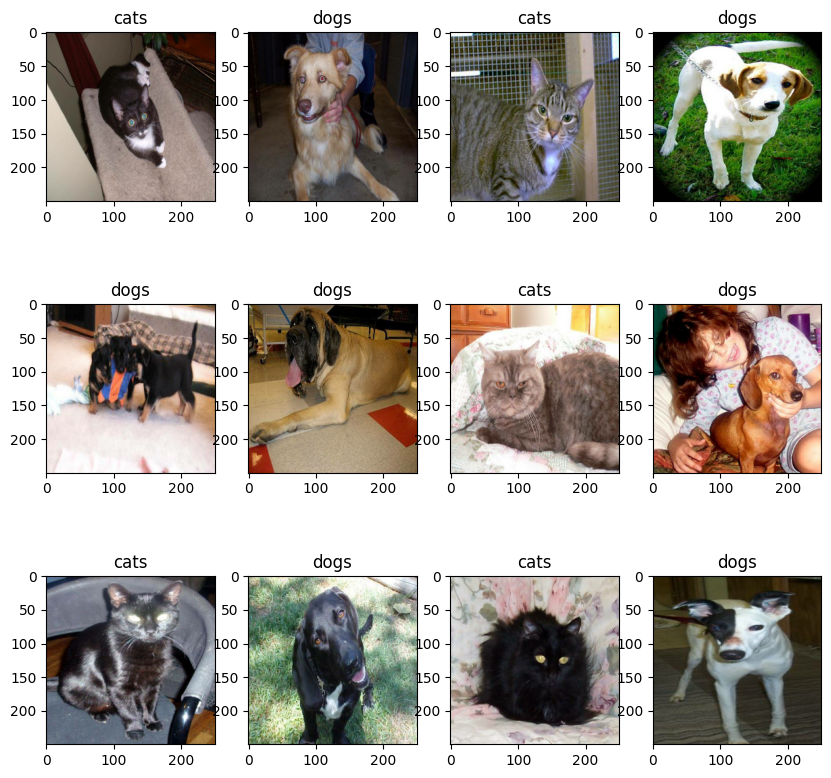

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
for image_batch,labels_batch in train_ds.take(1):
  for i in range(12):
    ax=plt.subplot(3,4,i+1)
    plt.imshow(image_batch[i].numpy().astype("uint8"))
    plt.title(class_names[labels_batch[i]])
    plt.axis

In [ ]:
input_shape=(image_size,image_size,3)
n_classess=2

In [ ]:
from tensorflow.keras import models
model=models.Sequential([
    layers.Rescaling(1./255,input_shape=input_shape),
    layers.Conv2D(32,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(128,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dropout(0.2),
    layers.Dense(128,activation='relu'),
    layers.Dense(n_classess,activation='softmax')
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 250, 250, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 248, 248, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 124, 124, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 122, 122, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 61, 61, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 59, 59, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 29, 29, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 107648)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 107648)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    13,779,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,872,578 (52.92 MB)

 Trainable params: 13,872,578 (52.92 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer="adam",loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),metrics=['accuracy'])

In [ ]:
earlt_stopping=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=5)

In [ ]:
history=model.fit(train_ds,epochs=epochs,validation_data=val_ds,callbacks=[earlt_stopping])

Epoch 1/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 43s 152ms/step - accuracy: 0.5370 - loss: 0.7190 - val_accuracy: 0.6365 - val_loss: 0.6671
Epoch 2/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 18s 88ms/step - accuracy: 0.6432 - loss: 0.6360 - val_accuracy: 0.6615 - val_loss: 0.6293
Epoch 3/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 74ms/step - accuracy: 0.7164 - loss: 0.5592 - val_accuracy: 0.6577 - val_loss: 0.6065
Epoch 4/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 21s 77ms/step - accuracy: 0.7820 - loss: 0.4633 - val_accuracy: 0.7239 - val_loss: 0.5943
Epoch 5/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 74ms/step - accuracy: 0.8606 - loss: 0.3244 - val_accuracy: 0.7027 - val_loss: 0.7263
Epoch 6/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 16s 78ms/step - accuracy: 0.9168 - loss: 0.2059 - val_accuracy: 0.7183 - val_loss: 0.8044
Epoch 7/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 74ms/step - accuracy: 0.9566 - loss: 0.1196 - val_accuracy: 0.7071 - val_loss: 1.0249
Epoch 8/10
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 76ms/step - accuracy: 0.9780 - loss: 0.0674 -

In [ ]:
scores=model.evaluate(test_ds)
scores

64/64 ━━━━━━━━━━━━━━━━━━━━ 13s 200ms/step - accuracy: 0.7182 - loss: 1.3068


[1.306753158569336, 0.7182402610778809]

In [ ]:
acc=history.history["accuracy"]
val_acc=history.history["val_accuracy"]
loss=history.history["loss"]
val_loss=history.history["val_loss"]

first image to predict
actual label: cats
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
predicted label: cats


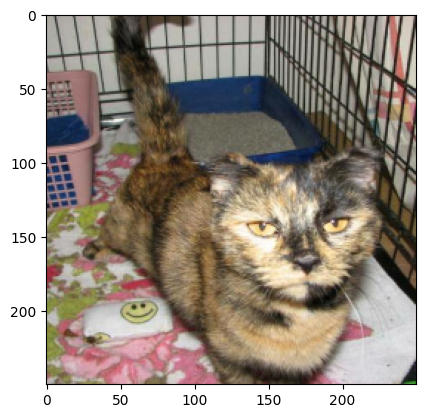

In [ ]:
#new prediction
import numpy as np
for image_batch,labels_batch in test_ds.take(1):
  first_image=image_batch[0].numpy().astype('uint8')
  first_label=labels_batch[0].numpy()
  print("first image to predict")
  plt.imshow(first_image)
  print("actual label:",class_names[first_label])

  batch_prediction=model.predict(image_batch)
  print("predicted label:",class_names[np.argmax(batch_prediction[0])])

first image to predict
actual label: dogs
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
predicted label: dogs


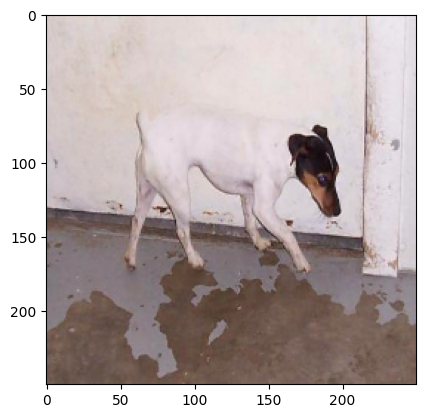

In [ ]:
#new predictio
for image_batch,labels_batch in test_ds.take(1):
  first_image=image_batch[5].numpy().astype('uint8')
  first_label=labels_batch[5].numpy()
  print("first image to predict")
  plt.imshow(first_image)
  print("actual label:",class_names[first_label])

  batch_prediction=model.predict(image_batch)
  print("predicted label:",class_names[np.argmax(batch_prediction[5])])

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array
import numpy as np

# Load the image with the correct target size expected by the model (250, 250)
img = load_img("/content/cat.jpg", target_size=(image_size, image_size))
img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_class = class_names[np.argmax(prediction)]

print("Predicted class:", predicted_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 806ms/step
Predicted class: cats
